In [7]:
# Kauã Santos Serafim de Oliveira - 2 Termo
# Hugo Jurazeky Pinheiro - 2 Termo

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import files

# Caso precise fazer o upload novamente:
# arquivos = files.upload()

# Corrigido o nome do arquivo para corresponder ao arquivo enviado
dados = pd.read_csv("diabetes_risk_dataset.csv")
display(dados.head(5))

,age,bmi,glucose_level,physical_activity_level,family_history,smoker,at_risk_diabetes
0,58,33.154816,71.049867,low,0,0,1
1,71,26.786882,125.964887,low,0,0,0
2,48,20.977319,61.876196,moderate,1,1,0
3,34,27.959924,137.648074,low,0,0,0
4,62,28.304175,65.879564,moderate,0,0,0


In [10]:
## Problema e Aplicação

# Qual problema pretendem resolver?
# R: Tentar prever quais indivíduos estão propícios a ter diabetes com base nos dados Informados

# Quem poderia utilizar o resultado e para quê?
# R: Pessoas que estão com índice de diabetes, tomar as providências para tentar amenizar o impacto da diabete

In [11]:
## Informações do Dataset

# Diabetes Risk Prediction
# https://www.kaggle.com/datasets/mansiaggarwal88/diabetes-risk-prediction
# Um conjunto de dados tabular abrangente com 15.000 perfis de pacientes para aprendizado de máquina
# Dados Fictícios/Sintéticos


In [13]:
## Conhecimento da Base

# Carregando o arquivo correto que está no seu ambiente
df = pd.read_csv("diabetes_risk_dataset.csv")

print("Quantidade de linhas:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])
print("Dimensões do dataset:", df.shape)

print()
print("Valores nulos por coluna:")
print(df.isnull().sum())

print()
print("Total de duplicatas:", df.duplicated().sum())

print()
print("=== VARIÁVEIS DO DATASET ===")
for coluna in df.columns:
    print(coluna)

Quantidade de linhas: 100000
Quantidade de colunas: 7
Dimensões do dataset: (100000, 7)

Valores nulos por coluna:
age                        0
bmi                        0
glucose_level              0
physical_activity_level    0
family_history             0
smoker                     0
at_risk_diabetes           0
dtype: int64

Total de duplicatas: 6

=== VARIÁVEIS DO DATASET ===
age
bmi
glucose_level
physical_activity_level
family_history
smoker
at_risk_diabetes


In [15]:
# Objetivo Da Previsão

# A coluna prevista é a "diabetes_risk", o problema é de regressão, já que tentaremos prever o risco de cada indivíduo ter diabetes
# "age, gender, bmi, family_history_diabetes, physical_activity_level, diet_type,	smoking_status,	alcohol_consumption,	hours_sleep_per_night,	stress_level,	fasting_blood_sugar,	hba1c_level,	blood_pressure_systolic,	blood_pressure_diastolic"

In [16]:
from sklearn.model_selection import train_test_split

# Colunas reais presentes no seu dataset carregado
colunas = ["age", "bmi", "glucose_level", "physical_activity_level", "family_history", "smoker"]
X = dados[colunas]
y = dados["at_risk_diabetes"]

# Como o modelo precisa de dados numéricos, aplicamos One-Hot Encoding na coluna categórica 'physical_activity_level'
X = pd.get_dummies(X, columns=["physical_activity_level"], drop_first=True)

# Reserve 20% para comparar as configurações; os outros 80% serão usados no treino.
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Treino:", len(X_treino), "Validação:", len(X_validacao))

Treino: 80000 Validação: 20000


# Escolha do modelo

# Algoritmo adequado e a regressão, porque estamos tentando prever o risco de cada indivíduo a ter diabetes

kaua nao sei me perdoa kkkk

In [20]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

modelo = make_pipeline(StandardScaler(), SVC(C=1, kernel="rbf", gamma="scale"))

modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_validacao)

print(f"Acurácia na validaçao: {accuracy_score(y_validacao, previsoes):.1%}")

Acurácia na validaçao: 89.4%


In [23]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd

# Quatro configurações de hiperparâmetros
configuracoes = [
    {"max_depth": 2, "min_samples_split": 2},
    {"max_depth": 5, "min_samples_split": 2},
    {"max_depth": 10, "min_samples_split": 2},
    {"max_depth": None, "min_samples_split": 5}
]

resultados = []

# Treinar e avaliar cada configuração utilizando as variáveis em português
for i, parametros in enumerate(configuracoes, start=1):

    modelo = DecisionTreeRegressor(
        **parametros,
        random_state=42
    )

    modelo.fit(X_treino, y_treino)

    previsoes = modelo.predict(X_validacao)

    mae = mean_absolute_error(y_validacao, previsoes)

    resultados.append({
        "Treinamento": i,
        "Profundidade": parametros["max_depth"],
        "Divisão mínima": parametros["min_samples_split"],
        "MAE": mae
    })

# Mostrar os resultados
tabela = pd.DataFrame(resultados)
print(tabela)

# Encontrar a melhor configuração
melhor = tabela.loc[tabela["MAE"].idxmin()]

print("\nMelhor configuração:")
print(melhor)

   Treinamento  Profundidade  Divisão mínima       MAE
0            1           2.0               2  0.168953
1            2           5.0               2  0.124185
2            3          10.0               2  0.117520
3            4           NaN               5  0.120333

Melhor configuração:
Treinamento        3.00000
Profundidade      10.00000
Divisão mínima     2.00000
MAE                0.11752
Name: 2, dtype: float64


,Configuração,Profundidade,Divisão mínima,MAE Treino,MAE Validação
0,Profundidade 2,2.0,2,0.1700,0.1690
1,Profundidade 5,5.0,2,0.1256,0.1242
2,Profundidade 10,10.0,2,0.1102,0.1175
3,Sem limite,NaN,5,0.0220,0.1203


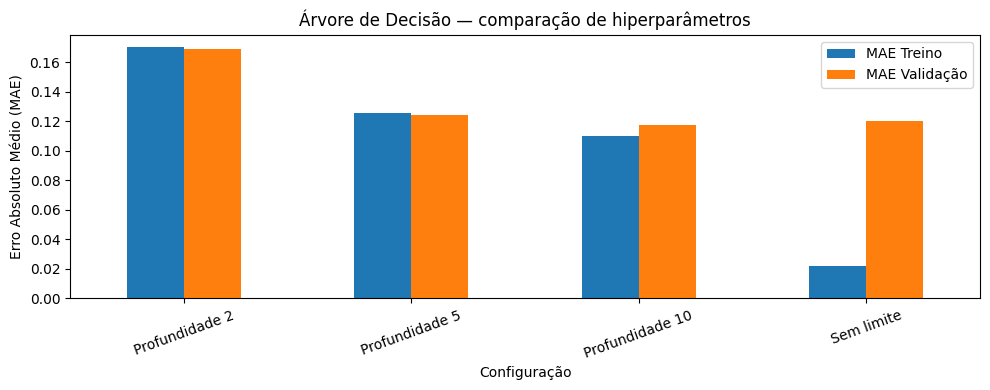


Melhor configuração:
Configuração      Profundidade 10
Profundidade                 10.0
Divisão mínima                  2
MAE Treino               0.110171
MAE Validação             0.11752
Name: 2, dtype: object


In [25]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd
import matplotlib.pyplot as plt

# Quatro configurações de hiperparâmetros
configuracoes = [
    {"nome": "Profundidade 2", "max_depth": 2, "min_samples_split": 2},
    {"nome": "Profundidade 5", "max_depth": 5, "min_samples_split": 2},
    {"nome": "Profundidade 10", "max_depth": 10, "min_samples_split": 2},
    {"nome": "Sem limite", "max_depth": None, "min_samples_split": 5}
]

resultados = []
modelos = []

# Treinar e avaliar cada configuração
for config in configuracoes:

    candidato = DecisionTreeRegressor(
        max_depth=config["max_depth"],
        min_samples_split=config["min_samples_split"],
        random_state=42
    )

    candidato.fit(X_treino, y_treino)

    # Guardar os modelos treinados
    modelos.append(candidato)

    # Fazer previsões
    previsoes_treino = candidato.predict(X_treino)
    previsoes_validacao = candidato.predict(X_validacao)

    # Calcular o MAE
    mae_treino = mean_absolute_error(
        y_treino, previsoes_treino
    )

    mae_validacao = mean_absolute_error(
        y_validacao, previsoes_validacao
    )

    resultados.append({
        "Configuração": config["nome"],
        "Profundidade": config["max_depth"],
        "Divisão mínima": config["min_samples_split"],
        "MAE Treino": mae_treino,
        "MAE Validação": mae_validacao
    })

# Mostrar a tabela de comparação
comparacao = pd.DataFrame(resultados)
display(comparacao.round(4))

# Gráfico de comparação dos erros
comparacao.set_index("Configuração")[
    ["MAE Treino", "MAE Validação"]
].plot.bar(figsize=(10, 4), rot=20)

plt.ylabel("Erro Absoluto Médio (MAE)")
plt.title("Árvore de Decisão — comparação de hiperparâmetros")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

# Encontrar a melhor configuração pela validação
melhor = comparacao.loc[
    comparacao["MAE Validação"].idxmin()
]

print("\nMelhor configuração:")
print(melhor)


Configuração escolhida: Profundidade 10
MAE do modelo de Referência (Média) na validação: 0.3287
MAE da Árvore de Decisão escolhida na validação: 0.1175


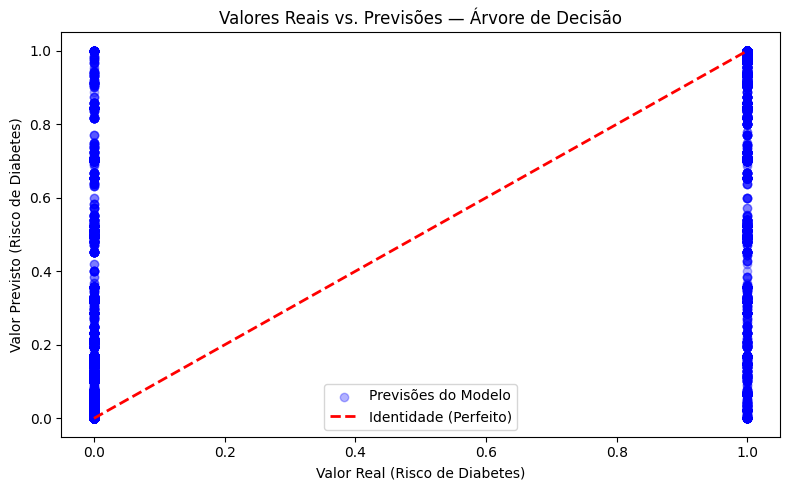

In [27]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# 1. Encontrar o índice com o MENOR MAE na validação
indice = comparacao["MAE Validação"].idxmin()
escolhida = configuracoes[indice]
modelo_escolhido = modelos[indice]

print("Configuração escolhida:", escolhida["nome"])
pred_validacao = modelo_escolhido.predict(X_validacao)

# 2. Criar um modelo de referência (Dummy) para Regressão (prevendo a média do treino)
referencia = DummyRegressor(strategy="mean")
referencia.fit(X_treino, y_treino)
pred_referencia = referencia.predict(X_validacao)

mae_referencia = mean_absolute_error(y_validacao, pred_referencia)
mae_modelo = mean_absolute_error(y_validacao, pred_validacao)

print(f"MAE do modelo de Referência (Média) na validação: {mae_referencia:.4f}")
print(f"MAE da Árvore de Decisão escolhida na validação: {mae_modelo:.4f}")

# 3. Gráfico para avaliar visualmente o resultado (Valores Reais vs. Previsões)
plt.figure(figsize=(8, 5))
plt.scatter(y_validacao, pred_validacao, alpha=0.3, color="blue", label="Previsões do Modelo")
plt.plot([y_validacao.min(), y_validacao.max()], [y_validacao.min(), y_validacao.max()], 'r--', lw=2, label="Identidade (Perfeito)")
plt.xlabel("Valor Real (Risco de Diabetes)")
plt.ylabel("Valor Previsto (Risco de Diabetes)")
plt.title("Valores Reais vs. Previsões — Árvore de Decisão")
plt.legend()
plt.tight_layout()
plt.show()